# Assignment 1 - looking at the results

In [1]:
from pathlib import Path
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
folder = Path('.')
plots = folder / 'output/analysis'
plots.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (6.5, 4)})

The original-model results are still in the baseline zip.
Q1/Q2 use v2; Q3 uses v3 (all four positions from the same run).
Q4 is the successful v4 run, using the original model.

Files: `output/baseline/results.zip`, `output/v2/benchmark_results.csv`,
`output/v3/Assignment1/benchmark_results.csv`, and
`output/q4/v4/Assignment1_Q4/q4_summary.csv`.

In [2]:
with zipfile.ZipFile(folder / 'output/baseline/results.zip') as z:
    with z.open('Assignment1/benchmark_results.csv') as f:
        original = pd.read_csv(f)

ranks = pd.read_csv(folder / 'output/v2/benchmark_results.csv').sort_values('rank')
positions = pd.read_csv(folder / 'output/v3/Assignment1/benchmark_results.csv')
q4_folder = folder / 'output/q4/v4/Assignment1_Q4'
q4 = pd.read_csv(q4_folder / 'q4_summary.csv').sort_values('layer')

# Check the saved runs
assert len(original) == 1 and original.iloc[0]['method'] == 'fresh'
assert ranks['rank'].tolist() == [16, 64, 256]
assert (ranks['component'] == 'default').all()
assert len(positions) == 4 and (positions['rank'] == 16).all()
assert set(positions['component']) == {'default', '25%', '50%', 'bot'}
assert q4['layer'].tolist() == [0, 7, 15]

for df in [original, ranks, positions]:
    assert (df['status'] == 'ok').all()
    assert (df['seed'] == 42).all()
    for dataset in ['gsm8k', 'math']:
        assert (df[dataset + '_total'] == 1000).all()
        difference = df[dataset + '_accuracy'] - df[dataset + '_correct'] / df[dataset + '_total']
        assert difference.abs().max() < 1e-10

## Q1 - original vs fine-tuned
Accuracy is stored as a fraction, so multiply by 100 for the report.
Each evaluation uses 1,000 examples per dataset.

In [3]:
q1 = pd.concat([original, ranks], ignore_index=True)
q1.index = ['Original', 'Rank 16', 'Rank 64', 'Rank 256']

accuracy = q1[['gsm8k_accuracy', 'math_accuracy']] * 100
accuracy.columns = ['GSM8K accuracy (%)', 'MATH accuracy (%)']
display(accuracy.round(1))
accuracy.to_csv(plots / 'q1_accuracy.csv', index_label='Model')

,GSM8K accuracy (%),MATH accuracy (%)
Original,3.5,0.1
Rank 16,15.7,3.8
Rank 64,20.6,4.6
Rank 256,27.2,5.3


All three ranks improve on the original model. Rank 256 gives the highest
accuracy here: 27.2% on GSM8K and 5.3% on MATH. MATH is still quite low.

Higher ranks give the adapter more trainable parameters, which could help
explain this. These runs only use seed 42, so other seeds might give a
different trend.


## Q2 - how long training took
Use `train_minutes`, not initialization or evaluation time.

In [4]:
times = ranks[['rank', 'train_minutes', 'trainable_parameters']].copy()
times.columns = ['Rank', 'Training time (min)', 'Trainable parameters']
display(times.round(2))
times.to_csv(plots / 'q2_training_time.csv', index=False)

,Rank,Training time (min),Trainable parameters
0,16,66.96,11272192
1,64,71.59,45088768
2,256,97.07,180355072


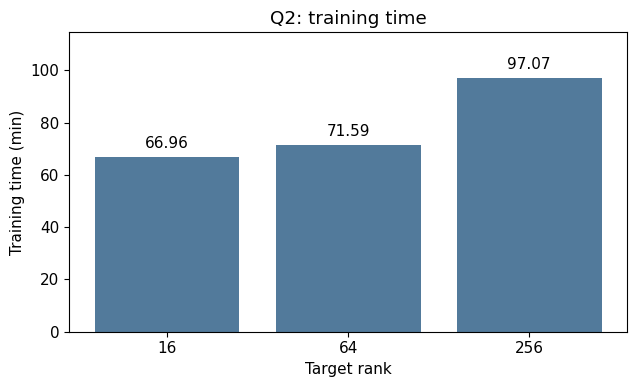

In [5]:
fig, ax = plt.subplots()
bars = ax.bar(ranks['rank'].astype(str), ranks['train_minutes'], color='#527A9B')
ax.bar_label(bars, fmt='%.2f', padding=4)
ax.set(xlabel='Target rank', ylabel='Training time (min)', title='Q2: training time')
ax.set_ylim(0, ranks['train_minutes'].max() * 1.18)
fig.tight_layout()
fig.savefig(plots / 'q2_training_time.png', dpi=300)
plt.show()
plt.close(fig)

In [6]:
extra_time = ranks.iloc[-1]['train_minutes'] - ranks.iloc[0]['train_minutes']
print(f'Rank 256 took {extra_time:.2f} minutes more than rank 16.')
print('Time increases with rank here, but it is not proportional to rank.')

Rank 256 took 30.10 minutes more than rank 16.
Time increases with rank here, but it is not proportional to rank.


Training takes longer as rank increases. More trainable parameters means
more work, but the rest of the model and data loading still take time too.
So training time does not increase in proportion to rank. There is only
one timing measurement for each setting.


## Q3 - which 16 singular values?

All four settings use rank 16. The 25% and 50% settings start that far
through the sorted singular values; they are not energy percentages.


In [7]:
q3 = positions.set_index('component').loc[['default', '25%', '50%', 'bot']]
labels = ['Top 16', '25% start', '50% start', 'Bottom 16']
q3_accuracy = q3[['gsm8k_accuracy', 'math_accuracy']] * 100
q3_accuracy.index = labels
q3_accuracy.columns = ['GSM8K accuracy (%)', 'MATH accuracy (%)']
display(q3_accuracy.round(1))
q3_accuracy.to_csv(plots / 'q3_accuracy.csv', index_label='SVD position')

,GSM8K accuracy (%),MATH accuracy (%)
Top 16,15.7,3.8
25% start,12.8,3.2
50% start,11.2,2.2
Bottom 16,11.5,2.8


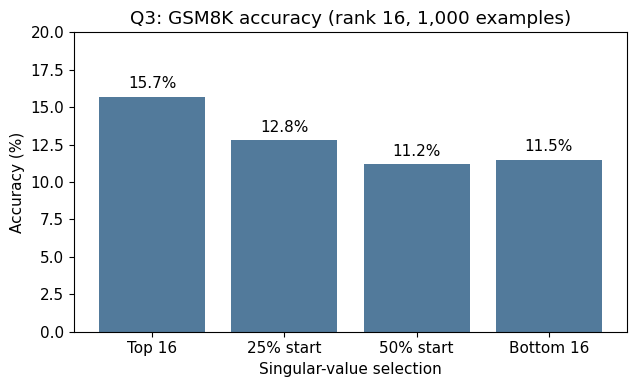

In [8]:
# GSM8K first
gsm = q3['gsm8k_accuracy'] * 100
fig, ax = plt.subplots()
bars = ax.bar(labels, gsm, color='#527A9B')
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in gsm], padding=4)
ax.set(xlabel='Singular-value selection', ylabel='Accuracy (%)',
       title='Q3: GSM8K accuracy (rank 16, 1,000 examples)')
ax.set_ylim(0, 20)
fig.tight_layout()
fig.savefig(plots / 'q3_gsm8k_accuracy.png', dpi=300)
plt.show()
plt.close(fig)

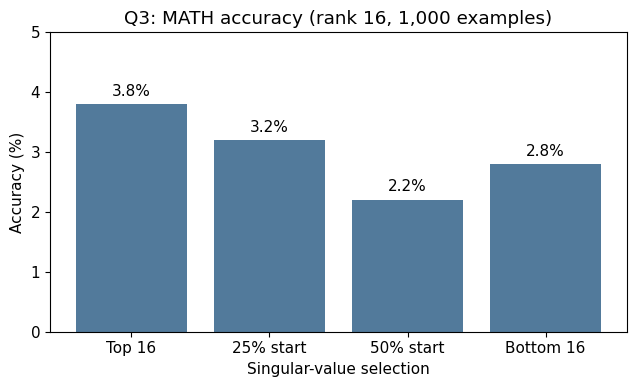

In [9]:
# MATH
math = q3['math_accuracy'] * 100
fig, ax = plt.subplots()
bars = ax.bar(labels, math, color='#527A9B')
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in math], padding=4)
ax.set(xlabel='Singular-value selection', ylabel='Accuracy (%)',
       title='Q3: MATH accuracy (rank 16, 1,000 examples)')
ax.set_ylim(0, 5)
fig.tight_layout()
fig.savefig(plots / 'q3_math_accuracy.png', dpi=300)
plt.show()
plt.close(fig)

Top 16 works best on both datasets: 15.7% on GSM8K and 3.8% on MATH.
Accuracy drops at the 25% and 50% positions. Bottom 16 is slightly better
than 50% (11.5 vs 11.2 on GSM8K, and 2.8 vs 2.2 on MATH), so it is not
a completely decreasing trend.

The leading singular directions seem to be a better starting point in
these runs. More seeds would be needed to tell whether the smaller
differences between the other settings are consistent.


## Q4 - original q_proj weights
Read the saved Q4 results. The minimum rank uses all singular values;
the plots show only the first 200.


In [10]:
rank_table = q4[['layer', 'minimum_rank_50pct', 'energy_before_rank_pct',
                 'energy_at_rank_pct', 'top200_energy_pct']].copy()
rank_table.columns = ['Layer', 'Minimum rank (50%)', 'Energy at previous rank (%)',
                      'Energy at chosen rank (%)', 'Top 200 energy (%)']
display(rank_table.round(4))
rank_table.to_csv(plots / 'q4_ranks.csv', index=False)

# Check the 50% crossing
assert (q4['energy_before_rank_pct'] < 50).all()
assert (q4['energy_at_rank_pct'] >= 50).all()

,Layer,Minimum rank (50%),Energy at previous rank (%),Energy at chosen rank (%),Top 200 energy (%)
0,0,62,49.9332,50.1701,71.2398
1,7,120,49.9926,50.2010,63.5434
2,15,84,49.8709,50.1154,68.8382


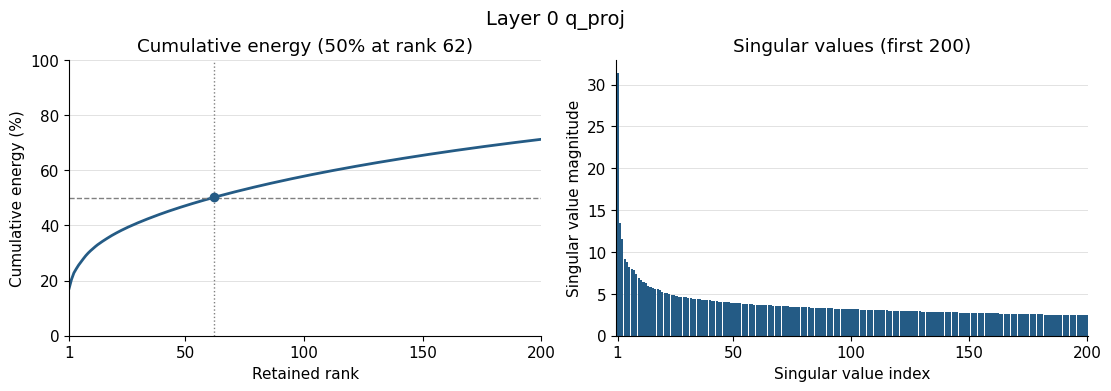

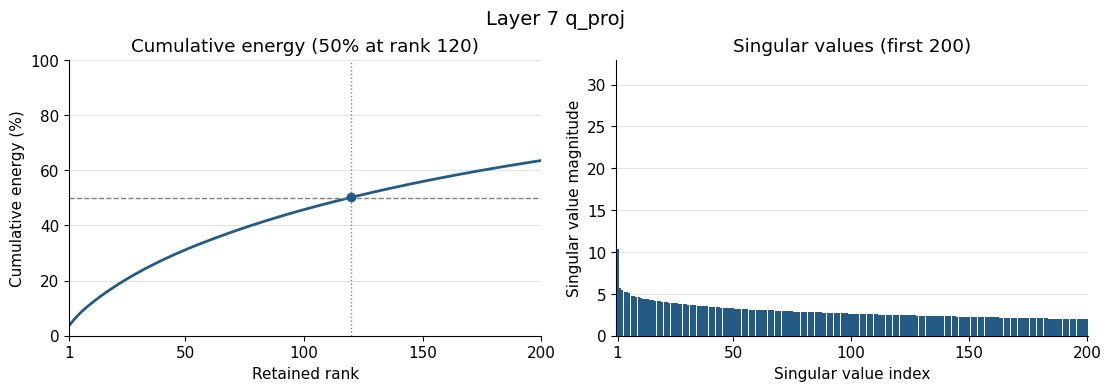

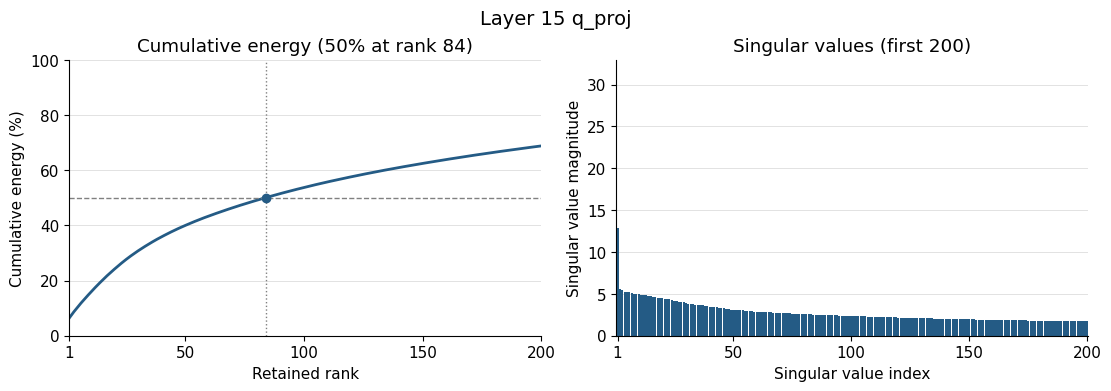

In [11]:
# Two plots per layer
spectra = {layer: pd.read_csv(q4_folder / f'layer_{layer}_q_proj_spectrum.csv')
           for layer in [0, 7, 15]}
magnitude_max = max(df['singular_value'].max() for df in spectra.values()) * 1.05

for layer in [0, 7, 15]:
    data = spectra[layer].head(200)
    result = q4.loc[q4['layer'] == layer].iloc[0]
    rank = int(result['minimum_rank_50pct'])
    x = data['singular_value_index']
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
    fig.suptitle(f'Layer {layer} q_proj', fontsize=14)

    axes[0].plot(x, data['cumulative_energy_pct'], color='#245B85', linewidth=2)
    axes[0].axhline(50, color='gray', linestyle='--', linewidth=1)
    if rank <= len(data):
        axes[0].axvline(rank, color='gray', linestyle=':', linewidth=1)
        axes[0].scatter(rank, result['energy_at_rank_pct'], color='#245B85', zorder=3)
    axes[0].set(title=f'Cumulative energy (50% at rank {rank})',
                xlabel='Retained rank', ylabel='Cumulative energy (%)',
                xlim=(1, 200), ylim=(0, 100))

    axes[1].bar(x, data['singular_value'], width=0.9, color='#245B85', linewidth=0)
    axes[1].set(title='Singular values (first 200)',
                xlabel='Singular value index', ylabel='Singular value magnitude',
                xlim=(0.5, 200.5), ylim=(0, magnitude_max))
    for ax in axes:
        ax.set_xticks([1, 50, 100, 150, 200])
        ax.grid(axis='y', color='#DDDDDD', linewidth=0.6)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)

    fig.savefig(plots / f'q4_layer_{layer}.png', dpi=300)
    plt.show()
    plt.close(fig)

The minimum ranks are 62, 120 and 84 for layers 0, 7 and 15.
Layer 0 reaches 50% with fewer components, while layer 7 needs the most.
The first 200 components keep about 71.24%, 63.54% and 68.84% of the energy.

This is weight energy, so keeping 50% does not mean keeping 50% of the
model's accuracy. It also does not tell us the best rank for fine-tuning.


### Unparsed answers

Accuracy uses all 1,000 questions as the denominator. Unparsed answers
count as incorrect. MATH has many unparsed answers, especially for the
original model, so its accuracy also depends on generation and parsing.


In [12]:
parsing = q1[['gsm8k_unparsed', 'math_unparsed']].copy()
parsing.columns = ['GSM8K unparsed (out of 1000)', 'MATH unparsed (out of 1000)']
display(parsing)
print('Done. Tables and Q2/Q3 plots saved in:', plots)

,GSM8K unparsed (out of 1000),MATH unparsed (out of 1000)
Original,15,956
Rank 16,0,543
Rank 64,0,472
Rank 256,0,454


Done. Tables and Q2/Q3 plots saved in: output\analysis
